# Gerchberg-Saxton ponderado consciente del dispositivo

**Pregunta:** ¿Puede el lazo de Gerchberg-Saxton ponderado absorber el crosstalk de píxeles y los otros límites del SLM dentro de sus iteraciones, en vez de combatirlos después, y cuánto supera a la línea base más fuerte en un dispositivo que los tiene?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** notebooks 02 y 03 de este tema y notebook 01 del tema 01
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Todo método de los notebooks hasta aquí calcula un holograma para un SLM ideal y confía en el resultado. Un SLM real cuantiza la fase, la difumina entre píxeles vecinos (el crosstalk del cristal líquido), tiene un factor de llenado menor que 1 y parpadea. La respuesta habitual es una cámara en el lazo, que corrige las trampas después. El componente BS-1 del producto plantea otra pregunta: poner el modelo del dispositivo dentro del lazo ponderado, de modo que el holograma se calcule para el dispositivo. Primero verás cuán equivocado está sobre su propio resultado un método de modelo ideal en el dispositivo del caso C08, luego ejecutarás los mejores métodos que ofrece la literatura, Gerchberg-Saxton ponderado de fase fija y gradiente conjugado a través del operador de crosstalk, y después B1 del producto, dos semillas cada uno, evaluados en el dispositivo. La última medición encuentra dónde vive la ventaja de B1 y dónde cuesta.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import device_of, setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.device import device_focal_field
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b1_device_wgs
from pipeline.model.holo.methods.optim import m13_crosstalk_cg

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def on_device(phi, setup, traps, device):
    """Eficiencia, uniformidad y dispersión (por ciento) de un holograma tal como lo muestra el dispositivo,
    promedio de cuatro sorteos del parpadeo."""
    rows = []
    for draw in range(4):
        field = device_focal_field(phi, setup, device, Rng(draw))
        i = metrics.trap_intensities(forward.trap_fields_from_fft(field, setup, traps))
        rows.append((metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)))
    return np.mean(rows, axis=0)

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio; los parámetros de crosstalk son los ajustados por Schroff et al. 2023 (https://doi.org/10.1038/s41598-023-30296-6).
- Archivo leído: `data/examples/cases.json`, caso C08: 64 trampas sobre un SLM de 128 por 128 píxeles con 4 bits de fase, crosstalk de ancho ajustado 1,24 y exponente 1,8, un factor de llenado de 0,85 y un parpadeo de 0,05 rad, y dos semillas contadas desde la semilla del caso.

In [2]:
# caso C08: 64 trampas en un SLM de 128 x 128 píxeles con 4 bits, crosstalk de píxel, factor de llenado 0.85 y algo de
# parpadeo
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C08_device_limited"]
setup = setup_of(rec)
device = device_of(rec)
target = target_of(rec)
traps = target.traps
budget = Budget(rec["budget"]["iterations"])
seeds = [rec["seed"], rec["seed"] + 1]
print(f"{len(traps)} trampas, {setup.n_pix} x {setup.n_pix} píxeles, {device.bit_depth} bits,")
print(f"crosstalk (sigma, q): {device.crosstalk}")
print(f"factor de llenado {device.fill_factor}, parpadeo {device.flicker_rad} rad")

64 trampas, 128 x 128 píxeles, 4 bits,
crosstalk (sigma, q): (1.24, 1.8)
factor de llenado 0.85, parpadeo 0.05 rad


## Método

El modelo de dispositivo del producto actúa sobre la fase mostrada en cuatro pasos: cuantización a $2^b$ niveles, una curva de respuesta, ruido de parpadeo y el crosstalk, una convolución circular de la fase sobremuestreada con un núcleo cuya función de transferencia es $\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]$, seguido de la apertura del píxel (Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6). Un holograma se juzga por el campo focal de esa fase mostrada. Los métodos de los notebooks anteriores no conocen el dispositivo: Gerchberg-Saxton ponderado de fase fija (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178) itera el modelo ideal y se detiene cuando es uniforme en el modelo ideal. Las métricas son las del tema 01, calculadas en el dispositivo y promediadas sobre cuatro sorteos del parpadeo, porque el parpadeo es aleatorio y un holograma debe ser bueno en el dispositivo promedio.

La primera celda ejecuta Gerchberg-Saxton ponderado (M06) y Gerchberg-Saxton ponderado de fase fija (M07) durante las 30 iteraciones del caso e imprime dos lecturas del mismo holograma: la dispersión que el método ve en el modelo ideal, que es la última entrada de su historial, y la dispersión que muestra el dispositivo.

In [3]:
# el modelo ideal frente al dispositivo: GS ponderado y WGS de fase fija se juzgan sobre el modelo ideal
ideal_runs = {}
for name, method in (("M06", m06_gsw), ("M07", m07_phase_fixed_wgs)):
    ideal_runs[name] = method.run(setup, target, budget=budget, rng=Rng(seeds[0]))
    last = ideal_runs[name].history[-1]
    shown = on_device(ideal_runs[name].phi, setup, traps, device)
    print(f"{name}: juicio propio sobre el modelo ideal: sigma = {last['rel_std']:.3f} %, e = {last['efficiency']:.4f}")
    print(f"     en el dispositivo: sigma = {shown[2]:.3f} %, e = {shown[0]:.4f}")

M06: juicio propio sobre el modelo ideal: sigma = 1.262 %, e = 0.8018
     en el dispositivo: sigma = 14.424 %, e = 0.6812
M07: juicio propio sobre el modelo ideal: sigma = 0.005 %, e = 0.7958
     en el dispositivo: sigma = 13.349 %, e = 0.6761


Una respuesta natural es que el método no ha iterado lo suficiente. La celda ejecuta M07 durante 100 iteraciones y lo lee en el dispositivo junto al holograma de 30 iteraciones.

In [4]:
# más iteraciones del método del modelo ideal no ayudan: 100 iteraciones de WGS de fase fija, leídas en el dispositivo
long_run = m07_phase_fixed_wgs.run(setup, target, budget=Budget(100), rng=Rng(seeds[0]))
for label, res in (("30", ideal_runs["M07"]), ("100", long_run)):
    shown = on_device(res.phi, setup, traps, device)
    print(f"M07 {label:>3s} iteraciones: en el dispositivo: sigma = {shown[2]:.3f} %")
    print(f"     u = {shown[1]:.4f}, e = {shown[0]:.4f}")

M07  30 iteraciones: en el dispositivo: sigma = 13.349 %
     u = 0.6922, e = 0.6761
M07 100 iteraciones: en el dispositivo: sigma = 13.349 %
     u = 0.6922, e = 0.6761


## Estado del arte

Dos líneas de trabajo responden a la brecha. La primera es la retroalimentación con cámara, que corrige las trampas después de hacer el holograma y que el producto emula en notebooks de los temas posteriores. La segunda pone el modelo de crosstalk dentro de la optimización: Schroff et al. (2023) lo usan con gradiente conjugado en potenciales moldeados, y M13 del producto es ese método para las trampas de este caso, con el gradiente a través de la adjunta del operador de crosstalk en forma cerrada. Es la línea base más fuerte para un dispositivo con crosstalk, pues optimiza directamente la intensidad consciente del dispositivo, al precio de muchas iteraciones; la línea base más fuerte para el modelo ideal es Gerchberg-Saxton ponderado de fase fija. La celda ejecuta M13 en el dispositivo e imprime la dispersión, la uniformidad y la eficiencia en el dispositivo.

B1 no parte en frío: primero corre 12 iteraciones de Gerchberg-Saxton ponderado del modelo ideal (M06) desde la superposición aleatoria de su semilla, y luego 4 iteraciones externas de 3 pasos de gradiente conjugado. Una prueba justa de la línea base más fuerte da a M13 el mismo inicio y el mismo número de pasos de gradiente conjugado: la celda calcula ese inicio con M06 (12 iteraciones, la misma semilla, por lo tanto la misma fase desde la que parte B1), corre M13 durante 12 iteraciones desde él con el dispositivo del caso y lee el resultado en el dispositivo. También corre M13 durante 12 iteraciones desde su propio inicio aleatorio, para mostrar cuánto vale el inicio para el gradiente conjugado. La celda también corre M13 durante 40 iteraciones desde el mismo inicio, para ver si más iteraciones bajarían su dispersión, y repite la corrida de 12 iteraciones desde el inicio de la segunda semilla, de modo que la comparación con B1 se apoye en dos semillas. El presupuesto igual es la comparación que hace este notebook.

In [5]:
# la otra manera de usar el modelo del dispositivo: gradiente conjugado a través del operador de crosstalk (M13),
# 12 iteraciones, desde el inicio de B1 de cada semilla (12 iteraciones de GS ponderado, misma semilla) y, en contraste,
# desde su propio inicio aleatorio
warm_starts = [m06_gsw.run(setup, target, budget=Budget(12), rng=Rng(s)).phi for s in seeds]
cg_runs = [
    m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(s), init=w)
    for s, w in zip(seeds, warm_starts)
]
cg_all = np.array([on_device(r.phi, setup, traps, device) for r in cg_runs])
cg_numbers = cg_all[0]
cold_run = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(seeds[0]))
cg_cold = on_device(cold_run.phi, setup, traps, device)
for label, row in (("desde el inicio de B1", cg_numbers), ("desde un inicio aleatorio", cg_cold)):
    print(f"M13 12 iteraciones {label}: en el dispositivo: sigma = {row[2]:.3f} %, u = {row[1]:.4f}, e = {row[0]:.4f}")
row = cg_all[1]
print(f"M13 12 iteraciones desde el inicio de B1, segunda semilla: sigma = {row[2]:.3f} %, "
      f"u = {row[1]:.4f}, e = {row[0]:.4f}")
# ¿bajan más iteraciones la dispersión de M13? 40 iteraciones desde el mismo inicio de la primera semilla
long_cg = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(40), rng=Rng(seeds[0]), init=warm_starts[0])
long_row = on_device(long_cg.phi, setup, traps, device)
print(f"M13 40 iteraciones desde el inicio de B1: sigma = {long_row[2]:.3f} %, "
      f"u = {long_row[1]:.4f}, e = {long_row[0]:.4f}")


M13 12 iteraciones desde el inicio de B1: en el dispositivo: sigma = 8.349 %, u = 0.8211, e = 0.6712
M13 12 iteraciones desde un inicio aleatorio: en el dispositivo: sigma = 57.314 %, u = 0.0054, e = 0.2001
M13 12 iteraciones desde el inicio de B1, segunda semilla: sigma = 7.743 %, u = 0.8252, e = 0.6768
M13 40 iteraciones desde el inicio de B1: sigma = 8.508 %, u = 0.8202, e = 0.6715


## Más allá del estado del arte

La afirmación BS-1 del producto: conservar los pesos de Gerchberg-Saxton ponderado, $w_m \leftarrow w_m\langle r\rangle/r_m$, con $r_m$ medido en el campo focal del dispositivo, y reemplazar la actualización de fase por unos pocos pasos de gradiente conjugado sobre la pérdida de intensidad consciente del dispositivo, a través del cuantizador de paso directo y del operador de crosstalk. Los pesos dan al lazo su memoria, y los pasos de gradiente le dan el dispositivo. La brecha que llena es que el modelo de crosstalk se había usado solo con gradiente conjugado en potenciales moldeados, nunca dentro de un lazo ponderado para arreglos de trampas (Schroff et al. 2023). El componente es B1 en el código. Las pruebas que siguen son las que pueden refutarlo: dos semillas contra Gerchberg-Saxton ponderado de fase fija, una semilla contra el gradiente conjugado con el dispositivo desde el mismo inicio y con el mismo número de pasos de gradiente, y un recorrido de la intensidad del crosstalk para ver de dónde viene la ventaja y qué cuesta.

La celda ejecuta B1, con 4 iteraciones externas de 3 pasos de gradiente conjugado cada una, para las dos semillas, y M07 para las mismas semillas, lee ambos en el dispositivo e imprime el promedio, el rango de la dispersión y las razones.

In [6]:
# la afirmación, BS-1: GS ponderado cuya actualización de fase son unos pocos pasos de gradiente conjugado a través
# del modelo del dispositivo
b1_runs = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s)) for s in seeds]
b1_numbers = np.array([on_device(r.phi, setup, traps, device) for r in b1_runs])
m07_runs = [m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
m07_numbers = np.array([on_device(r.phi, setup, traps, device) for r in m07_runs])
for name, rows in (("M07", m07_numbers), ("B1", b1_numbers)):
    e, u, sigma = rows.mean(axis=0)
    low, high = rows[:, 2].min(), rows[:, 2].max()
    print(f"{name}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.3f} % (rango {low:.3f} a {high:.3f})")
ratio = m07_numbers[:, 2].mean() / b1_numbers[:, 2].mean()
print(f"dispersión de M07 sobre la de B1: {ratio:.1f}")
print(f"eficiencia de B1 sobre la de M07: {b1_numbers[:, 0].mean() / m07_numbers[:, 0].mean():.3f}")
print(f"razón de dispersión M13 / B1 (mismo inicio y pasos), primera semilla: {cg_numbers[2] / b1_numbers[0, 2]:.2f}")
print(f"eficiencia de B1 sobre la de M13 con la primera semilla: {b1_numbers[0, 0] / cg_numbers[0]:.3f}")
ratios = cg_all[:, 2] / b1_numbers[:, 2]
print("razón de dispersión M13 / B1 (mismo inicio y pasos), por semilla: " + ", ".join(f"{x:.2f}" for x in ratios))
effs = b1_numbers[:, 0] / cg_all[:, 0]
print("eficiencia de B1 sobre la de M13, por semilla: " + ", ".join(f"{x:.3f}" for x in effs))

M07: e = 0.6785, u = 0.7086, sigma = 13.132 % (rango 12.915 a 13.349)
B1: e = 0.6538, u = 0.8692, sigma = 6.086 % (rango 5.449 a 6.723)
dispersión de M07 sobre la de B1: 2.2
eficiencia de B1 sobre la de M07: 0.964
razón de dispersión M13 / B1 (mismo inicio y pasos), primera semilla: 1.24
eficiencia de B1 sobre la de M13 con la primera semilla: 0.974
razón de dispersión M13 / B1 (mismo inicio y pasos), por semilla: 1.24, 1.42
eficiencia de B1 sobre la de M13, por semilla: 0.974, 0.966


El crosstalk es solo uno de los límites del dispositivo. La celda mantiene los 4 bits, el factor de llenado y el parpadeo y cambia solo el crosstalk, de ninguno a un ancho de 0,8 (fuerte; un ancho menor significa más difuminado), ejecutando B1 y leyendo M07 en cada dispositivo para la primera semilla.

In [7]:
# ¿dónde vive la ventaja? la intensidad del crosstalk de ninguna a fuerte, primera semilla, mismos bits y factor de
# llenado
rows = {}
levels = (("ninguno", None), ("1.24", (1.24, 1.8)), ("0.8", (0.8, 1.8)))
for label, crosstalk in levels:
    dev = replace(device, crosstalk=crosstalk)
    ours = b1_runs[0]
    if label != "1.24":
        ours = b1_device_wgs.run(setup, target, device=dev, budget=Budget(4), rng=Rng(seeds[0]))
    rows[label] = (on_device(m07_runs[0].phi, setup, traps, dev), on_device(ours.phi, setup, traps, dev))
    m07_row, b1_row = rows[label]
    factor = m07_row[2] / b1_row[2]
    print(f"{label:>5s}: M07 sigma = {m07_row[2]:7.3f} %, B1 sigma = {b1_row[2]:7.3f} %, razón {factor:.2f}")
    print(f"       M07 e = {m07_row[0]:.4f}, B1 e = {b1_row[0]:.4f}")

ninguno: M07 sigma =   3.953 %, B1 sigma =   0.757 %, razón 5.22
       M07 e = 0.7418, B1 e = 0.7405
 1.24: M07 sigma =  13.349 %, B1 sigma =   6.723 %, razón 1.99
       M07 e = 0.6761, B1 e = 0.6541
  0.8: M07 sigma =  24.540 %, B1 sigma =  24.906 %, razón 0.99
       M07 e = 0.6235, B1 e = 0.6203


La primera figura grafica la dispersión relativa de las trampas en el dispositivo de C08 para cinco corridas: el promedio de dos semillas para M07 y B1, y la primera semilla para M06 y para M13 desde los dos inicios.

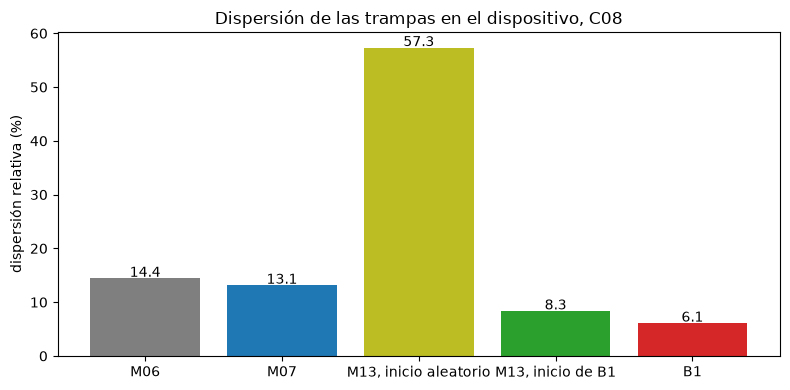

In [8]:
# la dispersión de las trampas en el dispositivo: promedio de dos semillas para M07 y B1, primera semilla para M06 y M13
fig, ax = plt.subplots(figsize=(8, 4))
bars = {
    "M06": on_device(ideal_runs["M06"].phi, setup, traps, device)[2],
    "M07": m07_numbers[:, 2].mean(),
    "M13, inicio aleatorio": cg_cold[2],
    "M13, inicio de B1": cg_numbers[2],
    "B1": b1_numbers[:, 2].mean(),
}
ax.bar(list(bars), list(bars.values()), color=["C7", "C0", "C8", "C2", "C3"])
for k, value in enumerate(bars.values()):
    ax.text(k, value + 0.3, f"{value:.1f}", ha="center")
ax.set_ylabel("dispersión relativa (%)")
ax.set_title("Dispersión de las trampas en el dispositivo, C08")
fig.tight_layout()
plt.show()


Entre los métodos que parten de una fase de Gerchberg-Saxton ponderado, la dispersión baja según cuánto del dispositivo conoce el método. M06, que no conoce nada de él, tiene una dispersión de 14,4 por ciento y M07, que converge sobre el modelo ideal, 13,1 por ciento en el promedio de dos semillas; ambos se juzgaron sobre el modelo ideal en 1,262 y 0,005 por ciento, y cien iteraciones no cambiaron un dígito del resultado de M07 en el dispositivo. M13, el gradiente conjugado a través del operador de crosstalk, depende de su inicio: desde su propio inicio aleatorio 12 iteraciones lo dejan en 57,3 por ciento, una corrida sin converger, y desde el inicio que usa B1, 12 iteraciones de GS ponderado, los mismos 12 pasos de gradiente lo llevan a 8,3 por ciento con la primera semilla, y 40 pasos lo dejan en 8,5. B1, que tiene el dispositivo dentro del lazo ponderado, termina en 6,1 por ciento. La figura no muestra la eficiencia que paga cada método, que imprime la tabla de arriba.

La segunda figura tiene dos paneles. A la izquierda, la razón de la dispersión de M07 a la de B1 contra el ancho del crosstalk, de ninguno al más fuerte. A la derecha, la eficiencia de ambos.

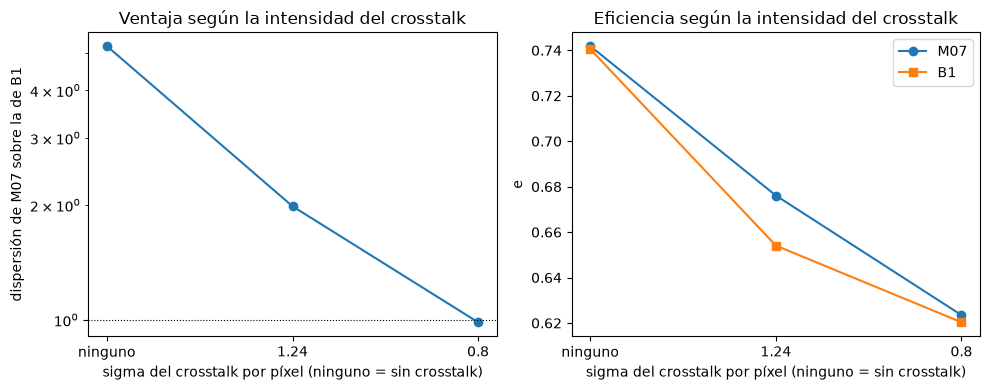

In [9]:
# la razón de las dos dispersiones según la intensidad del crosstalk, y la eficiencia que conserva cada método
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
labels = list(rows)
ax1.semilogy(labels, [rows[k][0][2] / rows[k][1][2] for k in labels], "o-")
ax1.axhline(1.0, color="k", lw=0.8, ls=":")
ax1.set_xlabel("sigma del crosstalk por píxel (ninguno = sin crosstalk)")
ax1.set_ylabel("dispersión de M07 sobre la de B1")
ax1.set_title("Ventaja según la intensidad del crosstalk")
ax2.plot(labels, [rows[k][0][0] for k in labels], "o-", label="M07")
ax2.plot(labels, [rows[k][1][0] for k in labels], "s-", label="B1")
ax2.set_xlabel("sigma del crosstalk por píxel (ninguno = sin crosstalk)")
ax2.set_ylabel("e")
ax2.set_title("Eficiencia según la intensidad del crosstalk")
ax2.legend()
fig.tight_layout()
plt.show()

La ventaja no es solo un efecto del crosstalk. Sin crosstalk alguno, con solo 4 bits, un factor de llenado de 0,85 y parpadeo, M07 tiene una dispersión de 3,953 por ciento y B1 de 0,757, una razón de 5,22, porque B1 ve también el cuantizador y la apertura. Al crecer el crosstalk ambos empeoran y la razón baja: 1,99 con el ancho de 1,24 del caso, y 0,99 con 0,8, donde B1 devuelve su inicio, 24,906 por ciento frente a 24,540: ahí cada iterado posterior al inicio cede más de una décima de la luz, y B1 nunca devuelve uno que lo haga. El panel derecho muestra el precio. Sin crosstalk las dos eficiencias difieren en 0,0013 (0,7405 frente a 0,7418); con 1,24 B1 tiene 0,6541 frente a 0,6761, y con 0,8 tiene 0,6203 frente a 0,6235, la eficiencia de su inicio, de modo que con crosstalk fuerte la uniformidad que B1 podría comprar cuesta más luz de la que su afirmación permite. El recorrido usa una semilla por punto y un número fijo de pasos, y no dice nada de dispositivos con otra profundidad de bits.

## Resultados

**Respuesta:** Sí, frente a ambas líneas base en este dispositivo, por un factor que depende de cuál. En el dispositivo de C08 los métodos del modelo ideal se equivocan sobre sí mismos: Gerchberg-Saxton ponderado de fase fija juzga su propio holograma con una dispersión de 0,005 por ciento y el dispositivo muestra 13,349 por ciento, y 100 iteraciones en vez de 30 no cambian nada. B1, con 4 iteraciones externas de 3 pasos de gradiente conjugado tras 12 iteraciones de GS ponderado, llega a 6,086 por ciento en promedio sobre dos semillas (5,449 a 6,723), frente a 13,132 por ciento de M07 (12,915 a 13,349), un factor de 2,2 con 0,964 de la eficiencia de M07; la uniformidad es 0,8692 frente a 0,7086. La línea base más fuerte, el gradiente conjugado a través del operador de crosstalk (M13), con el mismo inicio y los mismos 12 pasos de gradiente, llega a 8,349 por ciento con la primera semilla y 7,743 con la segunda, con eficiencias de 0,6712 y 0,6768, donde B1 tiene 6,723 y 5,449 por ciento: la dispersión de B1 es menor por un factor de 1,24 y 1,42, con 0,974 y 0,966 de la eficiencia de M13. Cuarenta iteraciones de M13 desde el primer inicio la dejan en 8,508 por ciento, no menos que con 12, de modo que más iteraciones no cierran la brecha. Desde su propio inicio aleatorio M13 termina en 57,314 por ciento tras esos 12 pasos, así que el inicio es la mayor parte de lo que necesita el gradiente conjugado. La ventaja sobre M07 depende del dispositivo: 5,22 veces sin crosstalk, 1,99 con el crosstalk del caso, y ninguna con un ancho de 0,8 (0,99), donde cada iterado posterior al inicio cedería más de una décima de la luz y B1 devuelve su inicio (eficiencia 0,6203 frente a 0,6235). BS-1 se sostiene en este dispositivo frente a Gerchberg-Saxton ponderado de fase fija por un factor de dos y frente al gradiente conjugado consciente del dispositivo por un factor de 1,24 a 1,42, con dos semillas en cada caso.

## Resumen

Un holograma calculado para un SLM ideal se equivoca sobre sí mismo en un dispositivo con 4 bits y crosstalk, por un factor de 11 en Gerchberg-Saxton ponderado y en órdenes de magnitud en la variante de fase fija, y más iteraciones no lo reparan. Poner el dispositivo en el lazo dentro de la iteración ponderada, como hace B1, reduce a la mitad la dispersión frente al estado del arte del modelo ideal con un costo de unos pocos por ciento de la eficiencia; con crosstalk fuerte la ganancia costaría más de una décima de la luz, y B1 entonces conserva su inicio, y supera al gradiente conjugado consciente del dispositivo desde el mismo inicio y con el mismo número de pasos de gradiente por un margen menor. Lo que no se prueba es un gradiente conjugado corrido más allá de 40 iteraciones (40 no bajaron su dispersión desde este inicio), otra profundidad de bits o factor de llenado, el parpadeo en el lazo y más de dos semillas.

## Referencias

- Schroff et al., "Accurate holographic light potentials using pixel crosstalk modelling", Scientific Reports 13 (2023), https://doi.org/10.1038/s41598-023-30296-6.
- Kim, Kim, Lee y Ahn, "Gerchberg-Saxton algorithm with phase fixing for tweezer arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.